In [110]:
from pypfopt import EfficientFrontier, risk_models, expected_returns
import pandas as pd

# 1. Charger les données des prix des actifs
data = pd.read_csv('../data/processed/df_historiques.csv', index_col='Date', parse_dates=True)
# 2. Calculer les rendements historiques moyens
returns = data.pct_change().dropna()  # Calcul des rendements journaliers
mean_returns = returns.mean()  # Rendements moyens pour chaque actif

top_8_assets = mean_returns.nlargest(23).index  

# Créer un sous-ensemble de données avec ces 8 actions
data_subset = data[top_8_assets]

# 4. Calcul des rendements espérés et de la matrice de covariance
mu = expected_returns.mean_historical_return(data_subset)  # Rendement espéré
S = risk_models.CovarianceShrinkage(data_subset).ledoit_wolf() # Matrice de covariance

# 5. Création du modèle d'optimisation
ef = EfficientFrontier(mu, S)
ef.add_constraint(lambda w: w <= 0.2)
# 6. Optimisation pour maximiser le ratio de Sharpe
weights = ef.min_volatility()

# 7. Calcul des poids optimaux et affichage des résultats
cleaned_weights = ef.clean_weights()
print("Poids optimaux pour les actions sélectionnées :")
print(cleaned_weights)

# 8. Performance du portefeuille optimisé avec un taux sans risque de 0,02
risk_free_rate = 0.04 # Taux sans risque
performance = ef.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

# 9. Optionnel : Sauvegarder les résultats
weights_df = pd.DataFrame(cleaned_weights.items(), columns=['Action', 'Poids'])
weights_df.to_csv('../results/poids_optimaux_top_8.csv', index=False)


Poids optimaux pour les actions sélectionnées :
OrderedDict({'TSLA': 0.00062, 'NVDA': 0.0, 'NFLX': 0.01111, 'UNH': 0.00974, 'MSFT': 0.0, 'ADBE': 0.0, 'AAPL': 0.0, 'AMZN': 0.04644, 'MA': 0.0, 'HD': 0.02987, 'V': 0.0, 'GOOGL': 0.00046, 'JPM': 0.0, 'BAC': 0.0, 'GS': 0.0, 'PEP': 0.08917, 'JNJ': 0.2, 'PFE': 0.13331, 'PG': 0.2, 'CMCSA': 0.0496, 'KO': 0.2, 'INTC': 0.0, 'DIS': 0.02968})
Expected annual return: 12.1%
Annual volatility: 14.7%
Sharpe Ratio: 0.55


In [15]:
# Affiche toutes les colonnes
pd.set_option('display.max_columns', None)
data.describe()

,AAPL,ADBE,AMZN,BAC,CMCSA,DIS,GOOGL,GS,HD,INTC,JNJ,JPM,KO,MA,MSFT,NFLX,NVDA,PEP,PFE,PG,TSLA,UNH,V
count,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000
mean,59.940109,232.403130,73.780049,21.604634,30.918636,106.957111,59.235031,196.547473,159.779893,34.620352,106.699737,79.404147,38.152744,184.805422,115.189942,239.053170,6.431811,97.486860,26.810235,86.163720,73.102271,211.486481,121.819809
std,48.682628,172.563698,53.289558,9.119899,9.526436,32.072281,34.467937,69.387835,84.432024,11.908923,30.898331,33.611707,9.165999,110.315878,89.227507,174.233526,7.355989,31.173920,8.055339,29.377067,101.969056,135.399576,63.207367
min,11.925922,37.730000,12.411500,8.808265,14.551998,45.420803,17.505644,104.180168,47.410694,14.622392,50.288303,31.886038,25.113424,47.362381,21.422949,13.144286,0.276414,48.566257,15.206195,48.328991,2.194000,42.569874,35.524097
25%,24.393016,79.612501,21.978374,13.055941,23.265710,89.537548,30.181158,143.297516,90.936798,25.350238,77.738369,46.631934,30.592270,85.165216,40.699942,89.404287,0.537192,72.402222,21.022897,62.008192,14.544000,100.387148,64.788071
50%,39.057543,184.305000,59.735750,21.039733,30.545339,101.592743,51.739882,179.201744,146.131927,30.587038,107.149368,80.045162,35.708931,147.294739,79.659084,190.705002,3.984123,90.495636,24.995100,71.557522,18.954333,198.510773,108.611893
75%,89.087120,347.574989,107.755125,26.824275,37.282691,123.452417,73.603357,212.268787,223.704216,44.754846,128.824448,100.709782,44.839856,298.144295,193.655846,361.797501,9.560841,118.195465,30.689500,111.073099,79.093498,280.611923,187.364578
max,178.879913,688.369995,186.570496,45.351665,55.510345,199.446121,149.125534,386.832520,383.101227,62.083344,170.243530,156.159195,60.509609,389.112122,333.767151,691.690002,33.313442,173.570251,52.609760,152.471893,409.970001,534.545837,244.034897


In [13]:
from pypfopt import EfficientFrontier, risk_models, expected_returns
import pandas as pd

# 1. Charger les données des prix des actifs
data = pd.read_csv('../data/predictions/prix_bigru.csv', index_col='Date', parse_dates=True)
# 2. Calculer les rendements historiques moyens
returns = data.pct_change().dropna()  # Calcul des rendements journaliers
mean_returns = returns.mean()  # Rendements moyens pour chaque actif

top_23_assets = mean_returns.nlargest(23).index  

# Créer un sous-ensemble de données avec ces 8 actions
data_subset = data[top_23_assets]

# 4. Calcul des rendements espérés et de la matrice de covariance
mu = expected_returns.mean_historical_return(data_subset)  # Rendement espéré
S = risk_models.CovarianceShrinkage(data_subset).ledoit_wolf()
  # Matrice de covariance

# 5. Création du modèle d'optimisation
ef = EfficientFrontier(mu, S)
ef.add_constraint(lambda w: w <= 0.2)

# 6. Optimisation pour maximiser le ratio de Sharpe
ef.max_sharpe(risk_free_rate=0.04)

# 7. Calcul des poids optimaux et affichage des résultats
cleaned_weights = ef.clean_weights()
print("Poids optimaux pour les actions sélectionnées :")
print(cleaned_weights)

# 8. Performance du portefeuille optimisé avec un taux sans risque de 0,04
risk_free_rate = 0.04 # Taux sans risque
performance = ef.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

# 9. Optionnel : Sauvegarder les résultats
weights_df = pd.DataFrame(cleaned_weights.items(), columns=['Action', 'Poids'])
weights_df.to_csv('../results/poids_optimaux_top_23.csv', index=False)


Poids optimaux pour les actions sélectionnées :
OrderedDict({'NVDA': 0.2, 'TSLA': 0.08565, 'NFLX': 0.03693, 'UNH': 0.2, 'MSFT': 0.17058, 'ADBE': 0.0, 'AAPL': 0.0, 'MA': 0.0, 'AMZN': 0.0, 'HD': 0.0, 'V': 0.0, 'GOOGL': 0.0, 'JPM': 0.0, 'BAC': 0.0, 'PEP': 0.18042, 'JNJ': 0.12642, 'GS': 0.0, 'PFE': 0.0, 'PG': 0.0, 'KO': 0.0, 'CMCSA': 0.0, 'DIS': 0.0, 'INTC': 0.0})
Expected annual return: 34.0%
Annual volatility: 12.5%
Sharpe Ratio: 2.39


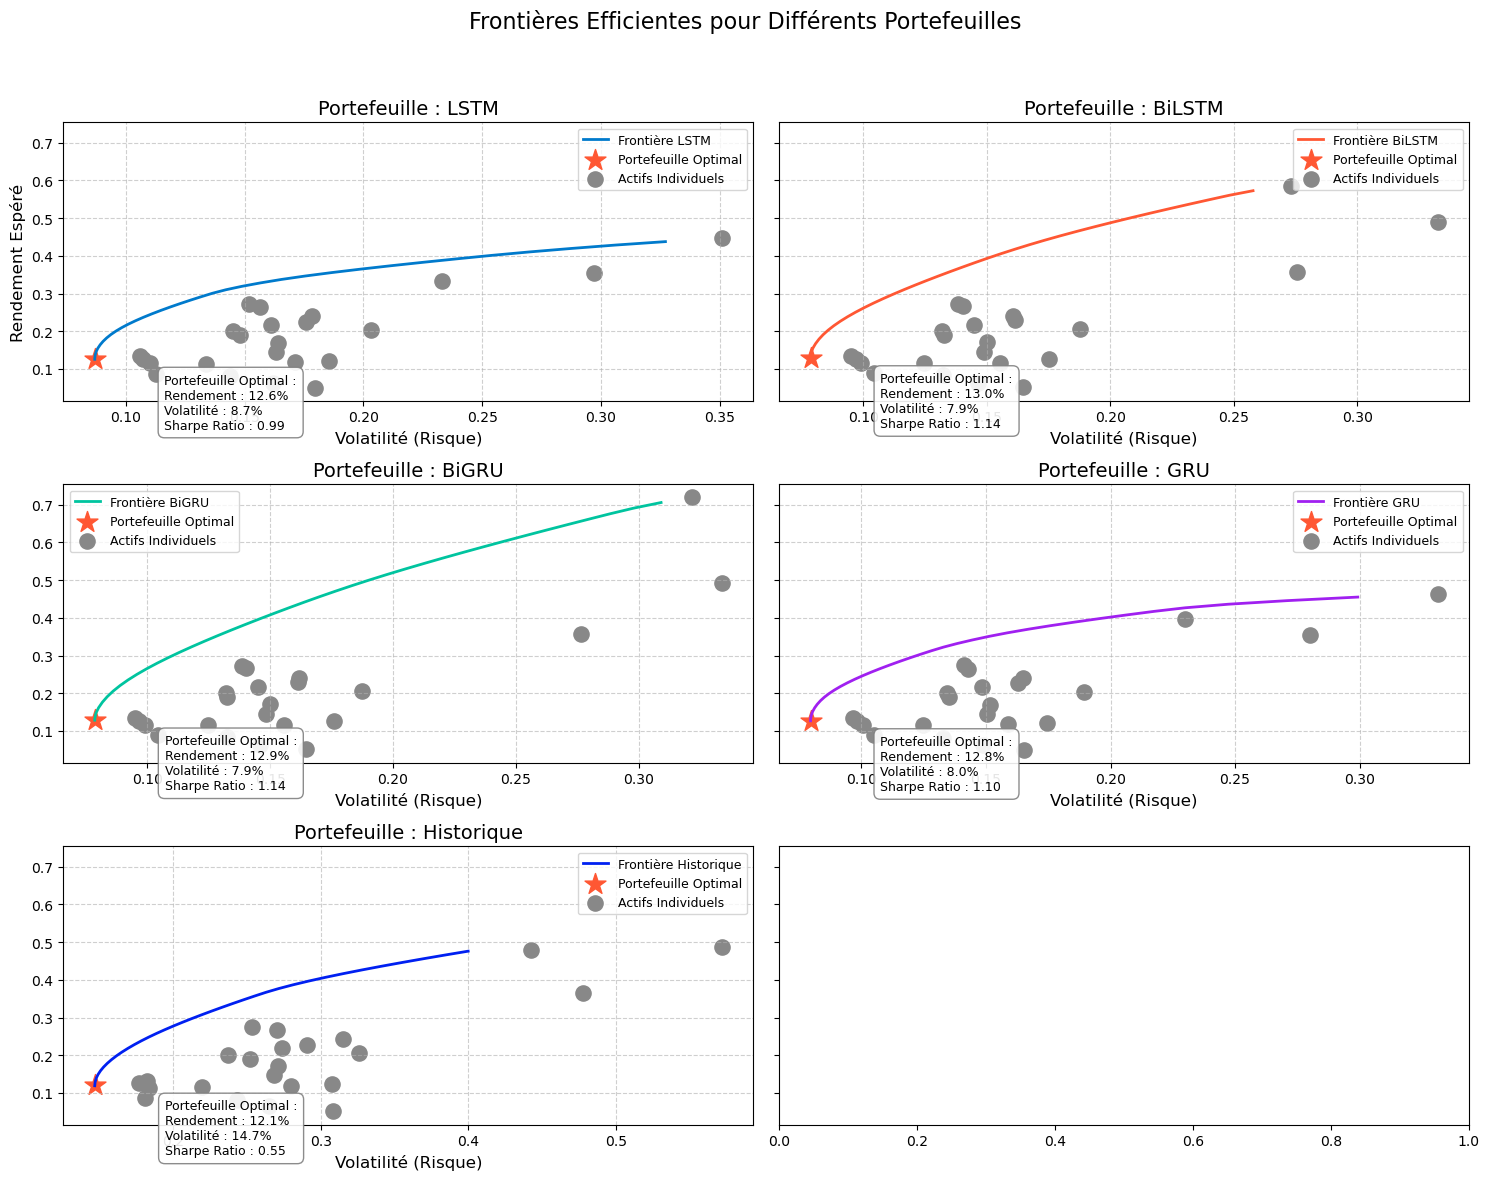

In [32]:
import pandas as pd
import numpy as np
from pypfopt import EfficientFrontier, risk_models, expected_returns
import matplotlib.pyplot as plt

# Charger les données pour chaque modèle et historique
data_bilstm_bigru = pd.read_csv('../data/predictions/prix_lstm.csv', index_col="Date", parse_dates=True)
data_bilstm = pd.read_csv('../data/predictions/prix_bilstm.csv', index_col='Date', parse_dates=True)
data_bigru = pd.read_csv('../data/predictions/prix_bigru.csv', index_col='Date', parse_dates=True)
data_gru = pd.read_csv('../data/predictions/prix_gru.csv', index_col='Date', parse_dates=True)
data_historique = pd.read_csv('../data/processed/df_historiques.csv', index_col='Date', parse_dates=True)
risk_free_rate=0.04
# Fonction pour calculer la frontière efficiente et les performances du portefeuille optimal
def calculate_portfolio(data):
    mu = expected_returns.mean_historical_return(data)
    S = risk_models.sample_cov(data)
    
    # Calculer la frontière efficiente
    returns, volatilities = [], []
    for target_return in np.linspace(0, max(mu), 50):
        try:
            # Créer une nouvelle instance d'EfficientFrontier
            ef = EfficientFrontier(mu, S)
            ef.efficient_return(target_return)
            ret, vol, _ = ef.portfolio_performance()
            returns.append(ret)
            volatilities.append(vol)
        except:
            continue
    
    # Calculer le portefeuille optimal (Max Sharpe Ratio)
    ef = EfficientFrontier(mu, S)  # Nouvelle instance pour le portefeuille optimal
    ef.add_constraint(lambda w: w <= 0.2)
    weights = ef.min_volatility()
    ret_sharpe, vol_sharpe, sharpe = ef.portfolio_performance(risk_free_rate=risk_free_rate)
    return mu, S, volatilities, returns, vol_sharpe, ret_sharpe, sharpe

# Calcul des données pour chaque modèle et historique
results_bilstm_bigru = calculate_portfolio(data_bilstm_bigru)
results_bilstm = calculate_portfolio(data_bilstm)
results_bigru = calculate_portfolio(data_bigru)
results_gru = calculate_portfolio(data_gru)
results_historique = calculate_portfolio(data_historique)

# Créer les sous-graphiques
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharey=True)
fig.suptitle("Frontières Efficientes pour Différents Portefeuilles", fontsize=16)

# Liste des résultats et des portefeuilles
portfolios = ["LSTM", "BiLSTM", "BiGRU", "GRU", "Historique"]
results = [results_bilstm_bigru, results_bilstm, results_bigru, results_gru, results_historique]
colors = ["#007ACC", "#FF5733", "#00C49F", "#A020F0", "#0020F1"]

for ax, portfolio, result, color in zip(axes.flatten(), portfolios, results, colors):
    mu, S, volatilities, returns, vol_sharpe, ret_sharpe, sharpe = result

    # Tracer la frontière efficiente
    ax.plot(volatilities, returns, label=f"Frontière {portfolio}", color=color, lw=2)

    # Ajouter le portefeuille optimal
    ax.scatter(vol_sharpe, ret_sharpe, marker="*", color="#FF5733", s=250, label="Portefeuille Optimal")

    # Ajouter les actifs individuels
    ax.scatter(np.sqrt(np.diag(S)), mu, marker='o', color="#888888", s=120, label="Actifs Individuels")

    # Annotations
    performance_text = f"""Portefeuille Optimal :
Rendement : {ret_sharpe:.1%}
Volatilité : {vol_sharpe:.1%}
Sharpe Ratio : {sharpe:.2f}"""
    ax.annotate(performance_text, xy=(vol_sharpe, ret_sharpe), xytext=(50, -50),
                textcoords='offset points', bbox=dict(facecolor='white', edgecolor='gray', 
                boxstyle='round,pad=0.5', alpha=0.9), fontsize=9)

    # Personnalisation
    ax.set_title(f"Portefeuille : {portfolio}", fontsize=14)
    ax.set_xlabel("Volatilité (Risque)", fontsize=12)
    if ax == axes[0, 0]:
        ax.set_ylabel("Rendement Espéré", fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(fontsize=9, frameon=True)

# Ajuster les marges
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Pour éviter que le titre ne chevauche les graphiques

# Sauvegarder l'image
plt.savefig('../results/figures/frontieres_efficientes_4_models.png', dpi=300, bbox_inches='tight')
plt.show()


In [104]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# 1. Vos données de résultats (MAPE et Directional Accuracy sont maintenant en format décimal)
data = {
    'Modèle': ['BiGRU', 'BiLSTM', 'GRU', 'LSTM'],
    'MSE': [5.5136, 5.6206, 7.2163, 8.4060],
    'MAE': [1.7896, 1.8049, 2.0300, 2.1942],
    'MAPE': [0.0143, 0.0145, 0.0162, 0.0175], # Converti de 1.43% à 0.0143
    'R²': [0.9940, 0.9939, 0.9922, 0.9909],
    'Directional Accuracy': [0.6340, 0.6313, 0.6127, 0.5782] # Converti de 63.40% à 0.6340
}

df = pd.DataFrame(data)

# 2. Transformer les données pour le traçage (format long)
df_melted = df.melt(id_vars=['Modèle'], var_name='Métrique', value_name='Valeur')

# 3. Préparer une colonne avec les valeurs formatées pour l'affichage sur les barres
# Les formats numériques sont pour les valeurs réelles (décimales)
format_map_numeric = {
    'MSE': '.4f',
    'MAE': '.4f',
    'MAPE': '.2f',  # Maintenant MAPE est un petit décimal
    'R²': '.4f',
    'Directional Accuracy': '.2f' # Maintenant Directional Accuracy est un décimal entre 0 et 1
}

df_melted['formatted_value'] = df_melted.apply(
    lambda row: (f'{row["Valeur"] * 100:{format_map_numeric[row["Métrique"]]}}%' # Multiplie par 100 pour l'affichage en %
                 if row["Métrique"] in ['MAPE', 'Directional Accuracy']
                 else f'{row["Valeur"]:{format_map_numeric[row["Métrique"]]}}'),
    axis=1
)

# 4. Créer le graphique en barres groupées
fig = px.bar(
    df_melted,
    x='Modèle',
    y='Valeur',
    color='Métrique',
    barmode='group', # Groupes de barres par modèle
    text='formatted_value', # Affiche la valeur formatée (avec %) sur les barres
    title='Comparaison des Performances des Modèles par Métrique',
    labels={
        'Modèle': 'Modèle Architectural',
        'Valeur': 'Valeur de la Métrique' # L'axe Y affiche les valeurs brutes (décimales pour les pourcentages)
    },
    category_orders={
        "Modèle": ['BiGRU', 'BiLSTM', 'GRU', 'LSTM'],
        "Métrique": ['MSE', 'MAE', 'MAPE', 'R²', 'Directional Accuracy'] # Ordre des métriques
    }
)

# 5. Personnalisation du graphique
fig.update_traces(
    textposition='outside', # Texte au-dessus des barres
    width=0.15 # Largeur des barres pour une meilleure séparation
)

fig.update_layout(
    height=700,
    width=1300,
    title_font_size=20,
    hovermode="x unified",
    yaxis_title="Valeur de la Métrique", # Le titre de l'axe Y reste générique
    legend_title="Métrique"
)

# L'annotation d'avertissement sur l'échelle n'est plus nécessaire, car le problème est atténué.

# 6. Afficher le graphique
fig.show()

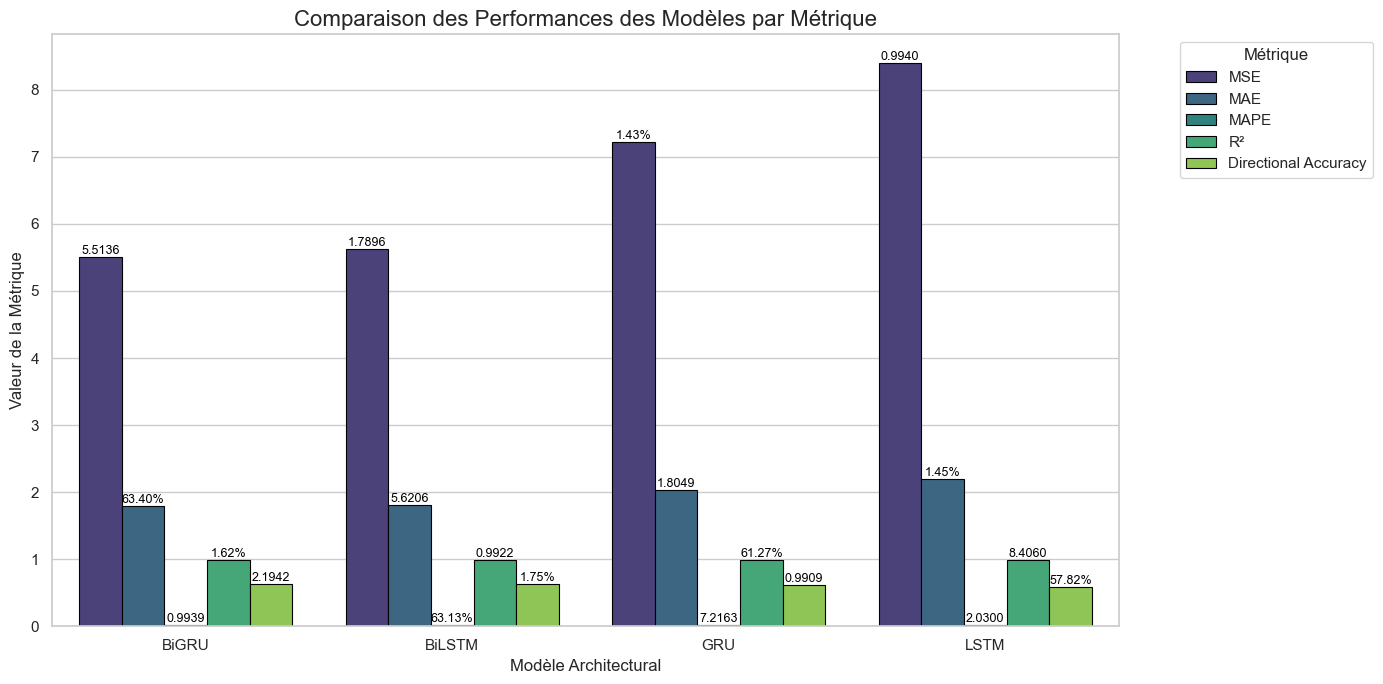

In [103]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Vos données de résultats (MAPE et Directional Accuracy en format décimal pour le traçage)
data = {
    'Modèle': ['BiGRU', 'BiLSTM', 'GRU', 'LSTM'],
    'MSE': [5.5136, 5.6206, 7.2163, 8.4060],
    'MAE': [1.7896, 1.8049, 2.0300, 2.1942],
    'MAPE': [0.0143, 0.0145, 0.0162, 0.0175], # Converti de 1.43% à 0.0143
    'R²': [0.9940, 0.9939, 0.9922, 0.9909],
    'Directional Accuracy': [0.6340, 0.6313, 0.6127, 0.5782] # Converti de 63.40% à 0.6340
}

df = pd.DataFrame(data)

# 2. Transformer les données pour le traçage (format long)
df_melted = df.melt(id_vars=['Modèle'], var_name='Métrique', value_name='Valeur')

# 3. Préparer une colonne avec les valeurs formatées pour l'affichage sur les barres
format_map_numeric = {
    'MSE': '.4f',
    'MAE': '.4f',
    'MAPE': '.2f',
    'R²': '.4f',
    'Directional Accuracy': '.2f'
}

df_melted['formatted_value'] = df_melted.apply(
    lambda row: (f'{row["Valeur"] * 100:{format_map_numeric[row["Métrique"]]}}%'
                 if row["Métrique"] in ['MAPE', 'Directional Accuracy']
                 else f'{row["Valeur"]:{format_map_numeric[row["Métrique"]]}}'),
    axis=1
)

# Configuration du style Seaborn
sns.set_theme(style="whitegrid")

# Créer la figure et les axes, en augmentant la largeur de la figure
plt.figure(figsize=(14, 7)) # Largeur augmentée de 12 à 14

# 4. Créer le graphique en barres groupées avec Seaborn
ax = sns.barplot(
    data=df_melted,
    x='Modèle',
    y='Valeur',
    hue='Métrique',
    palette='viridis',
    edgecolor='black',
    linewidth=0.8
)

# 5. Ajouter les étiquettes de texte sur les barres
models = df_melted['Modèle'].unique()
metrics = df_melted['Métrique'].unique()
n_metrics = len(metrics)

for i, model in enumerate(models):
    for j, metric in enumerate(metrics):
        data_point = df_melted[(df_melted['Modèle'] == model) & (df_melted['Métrique'] == metric)]
        
        if not data_point.empty:
            formatted_value = data_point['formatted_value'].iloc[0]

            patch_index = i * n_metrics + j
            if patch_index < len(ax.patches):
                p = ax.patches[patch_index]
                # Positionne le texte juste au-dessus de la barre
                ax.text(p.get_x() + p.get_width() / 2, p.get_height(), formatted_value,
                        ha='center', va='bottom', fontsize=9, color='black')

# 6. Personnalisation des titres et étiquettes
ax.set_title('Comparaison des Performances des Modèles par Métrique', fontsize=16)
ax.set_xlabel('Modèle Architectural', fontsize=12)
ax.set_ylabel('Valeur de la Métrique', fontsize=12)

# Ajuster la légende
plt.legend(title='Métrique', bbox_to_anchor=(1.05, 1), loc='upper left')

# Ajuster la mise en page pour éviter que les étiquettes ne soient coupées
plt.tight_layout()

# 7. Afficher le graphique
plt.show()

'predictions/prix_lstm.csv' chargé avec succès pour LSTM.
'predictions/prix_bilstm.csv' chargé avec succès pour BiLSTM.
'predictions/prix_bigru.csv' chargé avec succès pour BiGRU.
'predictions/prix_gru.csv' chargé avec succès pour GRU.
'df_historiques.csv' chargé avec succès pour Historique.


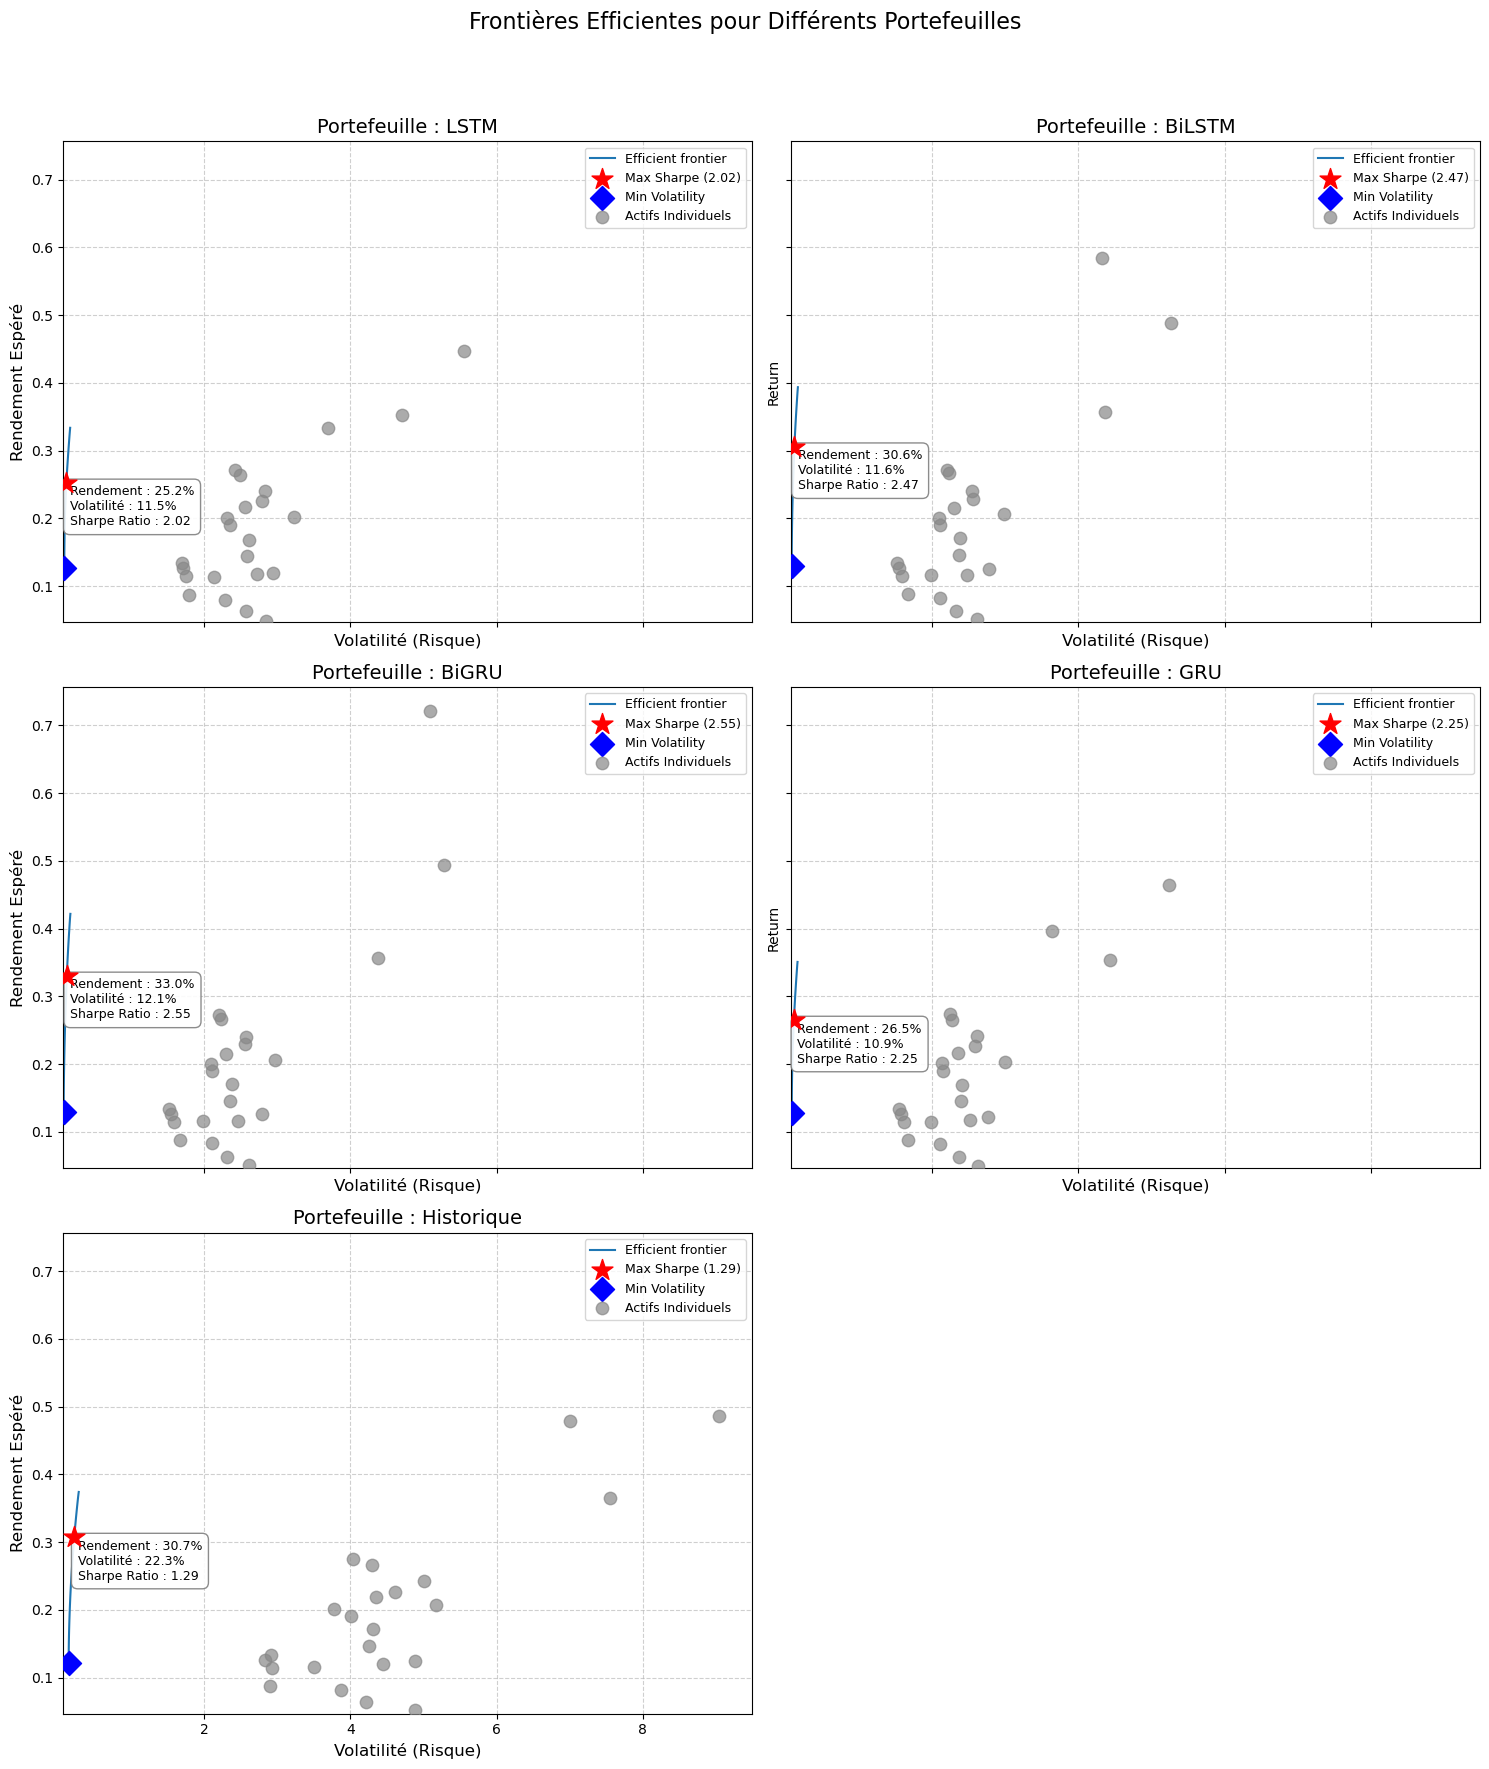

In [30]:
import pandas as pd
import numpy as np
from pypfopt import EfficientFrontier, risk_models, expected_returns
from pypfopt import plotting # Assurez-vous que plotting est importé
import matplotlib.pyplot as plt

# --- Configuration Globale ---
risk_free_rate = 0.02 # Taux sans risque annuel (ajustez si besoin)
max_weight_constraint = 0.2 # Contrainte de poids maximum par actif (20%)

# Fonction utilitaire pour charger les données avec gestion d'erreur
def load_data(file_path, df_name):
    try:
        df = pd.read_csv(file_path, index_col="Date", parse_dates=True)
        print(f"'{file_path}' chargé avec succès pour {df_name}.")
        # S'assurer que le DataFrame est numérique et contient des données valides pour les calculs
        df = df.select_dtypes(include=[np.number])
        if df.empty:
            print(f"Avertissement : Le DataFrame chargé depuis '{file_path}' est vide ou ne contient pas de données numériques.")
            return None
        return df
    except FileNotFoundError:
        print(f"Erreur : Le fichier '{file_path}' n'a pas été trouvé pour {df_name}.")
        print("Veuillez vérifier le chemin du fichier.")
        return None # Retourne None si le fichier n'est pas trouvé
    except Exception as e:
        print(f"Erreur lors du chargement ou du traitement de '{file_path}' pour {df_name} : {e}")
        return None

# --- Charger les données pour chaque modèle et historique ---
data_lstm = load_data('../data/predictions/prix_lstm.csv', "LSTM")
data_bilstm = load_data('../data/predictions/prix_bilstm.csv', "BiLSTM")
data_bigru = load_data('../data/predictions/prix_bigru.csv', "BiGRU")
data_gru = load_data('../data/predictions/prix_gru.csv', "GRU")
data_historique = load_data('../data/processed/df_historiques.csv', "Historique")


# Fonction pour calculer les paramètres de portefeuille et l'objet EfficientFrontier
def calculate_portfolio_params(data, risk_free_rate, max_weight_constraint):
    if data is None or data.empty:
        print("Données non disponibles ou vides pour le calcul du portefeuille.")
        return None # Retourne None si les données ne sont pas valides

    # Calcul des rendements attendus (annualisés par défaut par pypfopt)
    mu = expected_returns.mean_historical_return(data)
    
    # Calcul de la matrice de covariance robuste (Ledoit-Wolf)
    S = risk_models.CovarianceShrinkage(data).ledoit_wolf()
    
    # Créer une instance d'EfficientFrontier avec mu et S
    ef = EfficientFrontier(mu, S)
    
    # Ajouter la contrainte de poids maximum par actif
    ef.add_constraint(lambda w: w <= max_weight_constraint)

    # --- Calculer le portefeuille optimal (Max Sharpe Ratio) ---
    ef_sharpe = ef.deepcopy() # Utiliser une copie pour ne pas modifier l'objet principal ef
    try:
        ef_sharpe.max_sharpe(risk_free_rate=risk_free_rate)
        ret_sharpe, vol_sharpe, sharpe = ef_sharpe.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)
    except Exception as e:
        print(f"Impossible de calculer le portefeuille Max Sharpe : {e}")
        ret_sharpe, vol_sharpe, sharpe = np.nan, np.nan, np.nan # Gérer les échecs
    
    # --- Calculer le portefeuille à Volatilité Minimale ---
    ef_min_vol = ef.deepcopy() # Utiliser une copie
    try:
        ef_min_vol.min_volatility()
        ret_min_vol, vol_min_vol, _ = ef_min_vol.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)
    except Exception as e:
        print(f"Impossible de calculer le portefeuille Min Volatilité : {e}")
        ret_min_vol, vol_min_vol = np.nan, np.nan
    
    # --- Calcul des volatilités annualisées des actifs individuels pour le tracé ---
    individual_asset_volatilities = np.sqrt(np.diag(S)) * np.sqrt(252) # Annualise
    
    # Retourne l'objet EfficientFrontier configuré et les détails des portefeuilles optimaux
    return {
        "ef_object": ef,
        "mu": mu,
        "S": S,
        "sharpe_portfolio": {"return": ret_sharpe, "volatility": vol_sharpe, "sharpe": sharpe},
        "min_vol_portfolio": {"return": ret_min_vol, "volatility": vol_min_vol},
        "individual_asset_volatilities": individual_asset_volatilities
    }

# --- Exécution des calculs pour chaque portefeuille ---
all_results = {}

# Process each dataset
if data_lstm is not None:
    all_results["LSTM"] = calculate_portfolio_params(data_lstm, risk_free_rate, max_weight_constraint)
if data_bilstm is not None:
    all_results["BiLSTM"] = calculate_portfolio_params(data_bilstm, risk_free_rate, max_weight_constraint)
if data_bigru is not None:
    all_results["BiGRU"] = calculate_portfolio_params(data_bigru, risk_free_rate, max_weight_constraint)
if data_gru is not None:
    all_results["GRU"] = calculate_portfolio_params(data_gru, risk_free_rate, max_weight_constraint)
if data_historique is not None:
    all_results["Historique"] = calculate_portfolio_params(data_historique, risk_free_rate, max_weight_constraint)


# --- Préparer les limites d'axes globales pour une meilleure comparaison ---
all_volatilities = []
all_returns = []

for portfolio_name, result_data in all_results.items():
    if result_data is None:
        continue
    
    # Collecter les volatilités et rendements des points clés
    if not np.isnan(result_data["sharpe_portfolio"]["volatility"]):
        all_volatilities.append(result_data["sharpe_portfolio"]["volatility"])
        all_returns.append(result_data["sharpe_portfolio"]["return"])
    if not np.isnan(result_data["min_vol_portfolio"]["volatility"]):
        all_volatilities.append(result_data["min_vol_portfolio"]["volatility"])
        all_returns.append(result_data["min_vol_portfolio"]["return"])
    
    # Collecter les volatilités et rendements des actifs individuels
    if result_data["mu"] is not None and len(result_data["mu"]) > 0:
        all_volatilities.extend(result_data["individual_asset_volatilities"].tolist())
        all_returns.extend(result_data["mu"].tolist())

# Calculer les limites globales avec une petite marge
if all_volatilities and all_returns:
    global_min_vol = min(all_volatilities) * 0.95
    global_max_vol = max(all_volatilities) * 1.05
    global_min_ret = min(all_returns) * 0.95
    global_max_ret = max(all_returns) * 1.05
    
    # Ajustement si les plages sont trop étroites (ex: si min_vol ou min_ret est proche de zéro)
    if global_min_vol < 0: global_min_vol = 0
    if global_min_ret < -0.1: global_min_ret = -0.1 # Permettre des rendements négatifs sur l'axe y
    
else: # Fallback au cas où aucune donnée valide ne soit trouvée
    global_min_vol, global_max_vol = 0.0, 0.3
    global_min_ret, global_max_ret = 0.0, 0.3


# --- Créer les sous-graphiques pour visualiser les frontières ---
num_portfolios_to_plot = len([res for res in all_results.values() if res is not None])

if num_portfolios_to_plot == 0:
    print("Aucun portefeuille valide à tracer. Veuillez vérifier vos fichiers de données et les calculs.")
else:
    # Ajuster la disposition des subplots dynamiquement
    rows = int(np.ceil(num_portfolios_to_plot / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(15, 6 * rows), sharey=True, sharex=True)
    fig.suptitle("Frontières Efficientes pour Différents Portefeuilles", fontsize=16)

    # Aplatir la structure des axes pour itérer facilement
    axes_flat = axes.flatten() if num_portfolios_to_plot > 1 else [axes]

    colors = {
        "LSTM": "#007ACC",
        "BiLSTM": "#FF5733",
        "BiGRU": "#00C49F",
        "GRU": "#A020F0",
        "Historique": "#0020F1"
    }

    plot_idx = 0
    for portfolio_name, result_data in all_results.items():
        if result_data is None: # Passer si les données n'ont pas pu être calculées
            continue

        ax = axes_flat[plot_idx]
        ef_object = result_data["ef_object"]
        mu = result_data["mu"]
        sharpe_p = result_data["sharpe_portfolio"]
        min_vol_p = result_data["min_vol_portfolio"]
        individual_asset_volatilities = result_data["individual_asset_volatilities"]

        # --- TRACER LA FRONTIÈRE EFFICIENTE ---
        # Cette fonction de PyPortfolioOpt dessinera la ligne de la frontière
        plotting.plot_efficient_frontier(ef_object, ax=ax, show_assets=False, 
                                         show_optimal_portfolios=False)

        # Ajouter le portefeuille Max Sharpe Ratio
        if not np.isnan(sharpe_p["volatility"]):
            ax.scatter(sharpe_p["volatility"], sharpe_p["return"], 
                       marker="*", color="red", s=250, 
                       label=f"Max Sharpe ({sharpe_p['sharpe']:.2f})", zorder=5)

        # Ajouter le portefeuille à Volatilité Minimale
        if not np.isnan(min_vol_p["volatility"]):
            ax.scatter(min_vol_p["volatility"], min_vol_p["return"], 
                       marker="D", color="blue", s=150, 
                       label=f"Min Volatility", zorder=5) # Diamant pour Min Vol

        # Ajouter les actifs individuels
        if mu is not None and len(mu) > 0 and len(individual_asset_volatilities) == len(mu):
            ax.scatter(individual_asset_volatilities, mu, marker='o', color="#888888", s=80, 
                       label="Actifs Individuels", zorder=3, alpha=0.7)

        # Annotations pour le portefeuille optimal (Max Sharpe)
        if not np.isnan(sharpe_p["volatility"]):
            performance_text = f"""Rendement : {sharpe_p['return']:.1%}
Volatilité : {sharpe_p['volatility']:.1%}
Sharpe Ratio : {sharpe_p['sharpe']:.2f}"""
            
            # Positionnement flexible de l'annotation
            text_offset_x = 0.005 * (global_max_vol - global_min_vol)
            text_offset_y = 0.005 * (global_max_ret - global_min_ret)
            
            ax.annotate(performance_text, xy=(sharpe_p["volatility"], sharpe_p["return"]), 
                        xytext=(sharpe_p["volatility"] + text_offset_x, sharpe_p["return"] - text_offset_y),
                        textcoords='data',
                        bbox=dict(facecolor='white', edgecolor='gray', boxstyle='round,pad=0.5', alpha=0.9), 
                        fontsize=9,
                        ha='left', va='top')

        # Personnalisation des axes
        ax.set_title(f"Portefeuille : {portfolio_name}", fontsize=14)
        ax.set_xlabel("Volatilité (Risque)", fontsize=12)
        if plot_idx % 2 == 0: # N'afficher le ylabel que sur la colonne de gauche
            ax.set_ylabel("Rendement Espéré", fontsize=12)
            
        # Appliquer les limites globales aux axes
        ax.set_xlim(global_min_vol, global_max_vol)
        ax.set_ylim(global_min_ret, global_max_ret)

        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(fontsize=9, frameon=True)
        plot_idx += 1
    
    # Cacher les subplots vides s'il y a un nombre impair de portefeuilles
    for i in range(plot_idx, len(axes_flat)):
        fig.delaxes(axes_flat[i])

    # Ajuster les marges pour un affichage propre
    plt.tight_layout(rect=[0, 0, 1, 0.95]) 

    # Sauvegarder l'image
    plt.savefig('../results/figures/frontieres_efficientes_multi_portfolios.png', dpi=300, bbox_inches='tight')
    plt.show()